# Fig. S7c,d: minimal scattering model (chain joined to a two-leg ladder)


    Exact solution of the three-terminal junction of the Supplementary Information section *Minimal
    scattering model: reciprocity and mode selection*: a semi-infinite chain (one mode, L) joined to a
    semi-infinite two-leg ladder (modes b and ab). The notebook checks unitarity, S = Sᵀ, the sum rules,
    the leak identity R_b − R_L = T_{L→ab} − T_{b→ab}, the analytic expression for the asymmetry and the
    closed-form reflection amplitudes, and plots panels c and d of Fig. S7. No data files are needed.
    Panels a and b of the figure are schematics.

    Conventions: ħ = 1, lattice constant 1, energies in units of the chain hopping t.


Paper: Kandrai, K. *et al.* One-way electron mirrors from single-layer stacking shifts in rhombohedral graphite. Preprint at https://arxiv.org/abs/2610.20905 (2026).

In [1]:
import os
import sys
import requests
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import brentq
from scipy.stats import unitary_group

In [2]:
print('python', sys.version.split()[0])
print('numpy', np.__version__)
print('matplotlib', matplotlib.__version__)
print('scipy', scipy.__version__)

python 3.13.5
numpy 2.1.3
matplotlib 3.10.0
scipy 1.15.3


In [3]:
# figure style of the paper: scienceplots if it is installed, plain matplotlib otherwise
try:
    import scienceplots  # noqa: F401
    plt.style.use(['science', 'no-latex', 'nature', 'std-colors'])
except ImportError:
    pass
matplotlib.rcParams['pdf.fonttype'] = 42   # editable text in Inkscape / Illustrator
matplotlib.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['figure.dpi'] = 110

In [4]:
# Data files are downloaded from Zenodo into DATA_DIR if they are not there yet.
ZENODO_RECORD = '23419464'   # record number of the data set, https://zenodo.org/records/<ZENODO_RECORD>
DATA_DIR = 'data'

FILES = []


def get_data(filename, record=ZENODO_RECORD, data_dir=DATA_DIR):
    """Return the local path of a data file, downloading it from Zenodo first if needed."""
    path = os.path.join(data_dir, filename)
    if os.path.exists(path):
        return path
    os.makedirs(data_dir, exist_ok=True)
    url = f'https://zenodo.org/records/{record}/files/{requests.utils.quote(filename)}?download=1'
    print(f'Downloading {filename} ...')
    with requests.get(url, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(path, 'wb') as fh:
            for chunk in r.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
    print(f'  saved to {path}')
    return path


for f in FILES:
    get_data(f)

## The junction and its scattering matrix

Left lead: chain with hopping −t. Right lead: ladder with leg hopping −t and rung hopping −t⊥. The end
site of the chain couples to the two legs of the first rung with −τ_A and −τ_B. In the basis of the
bonding (b) and antibonding (ab) rung states the ladder decouples into two chains with on-site
energies ∓t⊥, coupled to the chain end by g_b = (τ_A + τ_B)/√2 and g_ab = (τ_A − τ_B)/√2.
The flux-normalized 3 × 3 scattering matrix follows from matching plane waves at the junction.

In [5]:
t, tperp, tauA, tauB = 1.0, 0.5, 1.2, 0.4   # parameters of Fig. S7
Ewin = (-(2 * t - tperp), 2 * t - tperp)     # all three channels propagate inside this window


def S_junction(E, t=t, tperp=tperp, tauA=tauA, tauB=tauB):
    """Flux-normalized 3x3 S matrix in the channel order (L, b, ab)."""
    gb, gab = (tauA + tauB) / np.sqrt(2), (tauA - tauB) / np.sqrt(2)
    kL, kb, kab = np.arccos(-E / (2 * t)), np.arccos(-(E + tperp) / (2 * t)), np.arccos(-(E - tperp) / (2 * t))
    v = np.array([2 * t * np.sin(kL), 2 * t * np.sin(kb), 2 * t * np.sin(kab)])
    eL, eb, eab = np.exp(1j * kL), np.exp(1j * kb), np.exp(1j * kab)
    A = np.array([[E + t * eL, gb * eb, gab * eab],
                  [gb, (E + tperp) * eb + t * eb ** 2, 0.0],
                  [gab, 0.0, (E - tperp) * eab + t * eab ** 2]], dtype=complex)
    rhs = np.array([[-E - t / eL, -gb, -gab],
                    [-gb / eb, -((E + tperp) / eb + t / eb ** 2), 0.0],
                    [-gab / eab, 0.0, -((E - tperp) / eab + t / eab ** 2)]], dtype=complex).T
    amp = np.linalg.solve(A, rhs)             # column i: outgoing amplitudes for injection in channel i
    S = amp * np.sqrt(np.outer(v, 1 / v))     # S_ji = sqrt(v_j / v_i) * amplitude
    return S, dict(kL=kL, kb=kb, kab=kab, gb=gb, gab=gab)


E = np.linspace(Ewin[0] + 0.02, Ewin[1] - 0.02, 400)
S = np.array([S_junction(e)[0] for e in E])
print('max |S^dag S - 1| :', np.max(abs(np.einsum('nij,nik->njk', S.conj(), S) - np.eye(3))))
print('max |S - S^T|     :', np.max(abs(S - np.transpose(S, (0, 2, 1)))))

max |S^dag S - 1| : 1.1102231382882377e-15
max |S - S^T|     : 8.895055758132639e-16


## Sum rules, the leak identity and the analytic expression

With R_L = |S_LL|², R_b = |S_bb|² and T_{i→j} = |S_ji|², unitarity and reciprocity give
R_b − R_L = T_{L→ab} − T_{b→ab}, and the closed-form amplitudes give
R_b − R_L = 4 g_ab² sin k_ab (t² sin k_L − g_b² sin k_b) / |D|² with
D = t² e^{−ik_L} − g_b² e^{ik_b} − g_ab² e^{ik_ab}.

In [6]:
P = abs(S) ** 2                       # P[n, j, i]: probability from channel i into channel j
RL, Rb = P[:, 0, 0], P[:, 1, 1]
TLb, TLab, TbL, Tbab = P[:, 1, 0], P[:, 2, 0], P[:, 0, 1], P[:, 2, 1]


def analytic_expression(E, t=t, tperp=tperp, tauA=tauA, tauB=tauB):
    _, c = S_junction(E, t, tperp, tauA, tauB)
    D = t ** 2 * np.exp(-1j * c['kL']) - c['gb'] ** 2 * np.exp(1j * c['kb']) - c['gab'] ** 2 * np.exp(1j * c['kab'])
    return 4 * c['gab'] ** 2 * np.sin(c['kab']) / abs(D) ** 2 * (t ** 2 * np.sin(c['kL']) - c['gb'] ** 2 * np.sin(c['kb']))


analytic = np.array([analytic_expression(e) for e in E])
print('sum rule, L column :', np.max(abs(RL + TLb + TLab - 1)))
print('sum rule, b column :', np.max(abs(Rb + TbL + Tbab - 1)))
print('reciprocity        :', np.max(abs(TLb - TbL)))
print('leak identity      :', np.max(abs((Rb - RL) - (TLab - Tbab))))
print('analytic expression:', np.max(abs((Rb - RL) - analytic)))

asym = lambda e: (lambda P: P[1, 1] - P[0, 0])(abs(S_junction(e)[0]) ** 2)
cond = lambda e: (lambda c: t ** 2 * np.sin(c['kL']) - c['gb'] ** 2 * np.sin(c['kb']))(S_junction(e)[1])
print(f'sign change of R_b - R_L at E/t = {brentq(asym, 0.3, 1.4):.6f}; '
      f't^2 sin k_L = g_b^2 sin k_b at E/t = {brentq(cond, 0.3, 1.4):.6f}')

tau_eq = (tauA + tauB) / 2    # two-port limit g_ab = 0, same g_b
S2 = np.array([S_junction(e, tauA=tau_eq, tauB=tau_eq)[0] for e in E])
print('g_ab = 0: max |R_L - R_b| =', np.max(abs(abs(S2[:, 0, 0]) ** 2 - abs(S2[:, 1, 1]) ** 2)))

sum rule, L column : 8.881784197001252e-16
sum rule, b column : 1.1102230246251565e-15
reciprocity        : 1.5543122344752192e-15
leak identity      : 6.106226635438361e-16
analytic expression: 4.440892098500626e-16
sign change of R_b - R_L at E/t = 0.953982; t^2 sin k_L = g_b^2 sin k_b at E/t = 0.953982
g_ab = 0: max |R_L - R_b| = 3.885780586188048e-16


## Panel c: the reflection probabilities

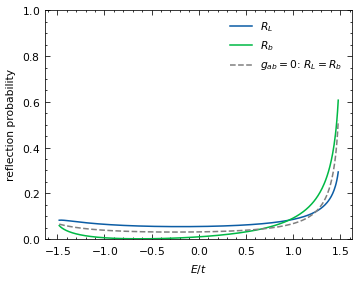

In [7]:
fig, ax = plt.subplots(figsize=(3.6, 2.7))
ax.plot(E, RL, label='$R_L$')
ax.plot(E, Rb, label='$R_b$')
ax.plot(E, abs(S2[:, 0, 0]) ** 2, '--', color='0.5', label=r'$g_{ab}=0$: $R_L = R_b$')
ax.set_xlabel('$E/t$'); ax.set_ylabel('reflection probability'); ax.set_ylim(0, 1)
ax.legend(frameon=False)
plt.show()

## Panel d: the leak difference and the analytic expression

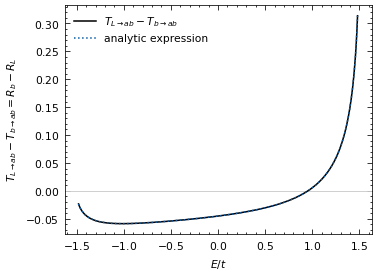

In [8]:
fig, ax = plt.subplots(figsize=(3.6, 2.7))
ax.axhline(0, color='0.8', lw=0.6)
ax.plot(E, TLab - Tbab, 'k', label=r'$T_{L\to ab} - T_{b\to ab}$')
ax.plot(E, analytic, ':', label='analytic expression')
ax.set_xlabel('$E/t$'); ax.set_ylabel(r'$T_{L\to ab} - T_{b\to ab} = R_b - R_L$')
ax.legend(frameon=False)
plt.show()

## Closed-form reflection amplitudes

S_LL = (g_b² e^{ik_b} + g_ab² e^{ik_ab} − t² e^{ik_L}) / D and
S_bb = (g_b² e^{−ik_b} + g_ab² e^{ik_ab} − t² e^{−ik_L}) / D, checked against the exact solution on
random parameters.

In [9]:
rng = np.random.default_rng(0)
worst = 0.0
for _ in range(2000):
    tp = rng.uniform(0.1, 0.9); tA = rng.uniform(0.2, 1.5); tB = rng.uniform(0.2, 1.5)
    gb, gab = (tA + tB) / np.sqrt(2), (tA - tB) / np.sqrt(2)
    e = rng.uniform(-2 + tp + 1e-3, 2 - tp - 1e-3)
    Sx, c = S_junction(e, tperp=tp, tauA=tA, tauB=tB)
    kL, kb, kab = c['kL'], c['kb'], c['kab']
    eL, eb, eab = np.exp(1j * kL), np.exp(1j * kb), np.exp(1j * kab)
    D = 1 / eL - gb ** 2 * eb - gab ** 2 * eab
    SLL = (gb ** 2 * eb + gab ** 2 * eab - eL) / D
    Sbb = (gb ** 2 / eb + gab ** 2 * eab - 1 / eL) / D
    worst = max(worst, abs(abs(SLL) ** 2 - abs(Sx[0, 0]) ** 2), abs(abs(Sbb) ** 2 - abs(Sx[1, 1]) ** 2))
print(f'max deviation of |S_LL|^2, |S_bb|^2 over 2000 parameter sets: {worst:.1e}')
assert worst < 1e-10

max deviation of |S_LL|^2, |S_bb|^2 over 2000 parameter sets: 1.0e-15


## Three-terminal statement

For random symmetric unitary 3 × 3 matrices S = U Uᵀ (U Haar distributed) the identity
R_2 − R_1 = T_{1→3} − T_{2→3} holds for every sample, and the two reflections differ generically.

identity, max deviation: 2.192690473634684e-15
mean |R_1 - R_2| = 0.252; fraction with |R_1 - R_2| < 0.01: 0.058


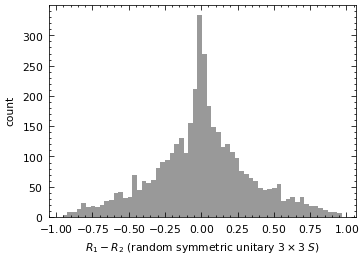

In [10]:
rng = np.random.default_rng(0)
S_rand = np.array([(lambda U: U @ U.T)(unitary_group.rvs(3, random_state=rng)) for _ in range(4000)])
Pr = abs(S_rand) ** 2
ident = (Pr[:, 1, 1] - Pr[:, 0, 0]) - (Pr[:, 2, 0] - Pr[:, 2, 1])
dR = Pr[:, 0, 0] - Pr[:, 1, 1]
print('identity, max deviation:', np.max(abs(ident)))
print(f'mean |R_1 - R_2| = {np.mean(abs(dR)):.3f}; fraction with |R_1 - R_2| < 0.01: {np.mean(abs(dR) < 0.01):.3f}')
fig, ax = plt.subplots(figsize=(3.6, 2.5))
ax.hist(dR, bins=60, color='0.6')
ax.set_xlabel('$R_1 - R_2$ (random symmetric unitary $3\\times3$ $S$)'); ax.set_ylabel('count')
plt.show()